In [1]:
import os, sys
import warnings
warnings.filterwarnings('ignore')
from IPython.display import display, Markdown, Math
import numpy as np
import pandas as pd
import networkx as nx
from scipy.stats import norm
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

# Versión local de la librería: se busca src/pmule.py subiendo desde el directorio actual
_aqui = os.path.abspath('.')
while _aqui != os.path.dirname(_aqui) and not os.path.isfile(os.path.join(_aqui, 'src', 'pmule.py')):
    _aqui = os.path.dirname(_aqui)
sys.path.append(os.path.join(_aqui, 'src'))
from pmule import (PredecessorTable, ProjectGraph, EarnedValue,
                   pinta_tikz, plot_cargas, plot_curvas_valor_ganado,
                   tanto_por_uno, ordena_rutas)

GANTT_PARAMS = dict(arrows=True)   # flechas de prelación en los diagramas de Gantt (rojas las críticas)

In [2]:
# Funciones auxiliares para mostrar los cálculos intermedios paso a paso
from itertools import combinations as _combinations


def detalle_tiempos_nodos(proyecto, duraciones):
    """Tiempos tempranos y tardíos de los nodos con los candidatos que se comparan en cada uno."""
    G = proyecto.pert_graph
    d = {data['activity']: (0 if data['activity'].startswith('@') else int(duraciones[data['activity']]))
         for _, _, data in G.edges(data=True)}
    nodos = list(proyecto.nodes)
    early, filas = {}, []
    for j in nodos:
        entrantes = [(i, data['activity']) for i, _, data in G.in_edges(j, data=True)]
        if not entrantes:
            early[j] = 0
            filas.append({'nodo': j, 'candidatos t_i + d_ij': 'nodo inicial', 'tiempo temprano = máx': 0})
            continue
        cand = {f'{a}: {early[i]} + {d[a]} = {early[i] + d[a]}': early[i] + d[a] for i, a in entrantes}
        early[j] = max(cand.values())
        filas.append({'nodo': j, 'candidatos t_i + d_ij': '; '.join(cand), 'tiempo temprano = máx': early[j]})
    tempranos = pd.DataFrame(filas).set_index('nodo')
    late, filas = {}, []
    for i in reversed(nodos):
        salientes = [(j, data['activity']) for _, j, data in G.out_edges(i, data=True)]
        if not salientes:
            late[i] = early[i]
            filas.append({'nodo': i, 'candidatos t*_j − d_ij': 'nodo final (= su tiempo temprano)', 'tiempo tardío = mín': late[i]})
            continue
        cand = {f'{a}: {late[j]} − {d[a]} = {late[j] - d[a]}': late[j] - d[a] for j, a in salientes}
        late[i] = min(cand.values())
        filas.append({'nodo': i, 'candidatos t*_j − d_ij': '; '.join(cand), 'tiempo tardío = mín': late[i]})
    tardios = pd.DataFrame(filas).set_index('nodo')
    return tempranos, tardios


def detalle_holguras(calendario, prelaciones):
    """Cómo se obtiene cada fecha y cada holgura a partir de las vecinas."""
    pred = prelaciones.immediate_predecessor
    suc = {a: sorted(s for s, ps in pred.items() if a in ps) for a in calendario.index}
    fin = int(calendario['fin_mas_temprano'].max())
    filas = []
    for a in calendario.index:
        ES, EF = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'fin_mas_temprano'])
        LS, LF = int(calendario.loc[a, 'inicio_mas_tardio']), int(calendario.loc[a, 'fin_mas_tardio'])
        dur = int(calendario.loc[a, 'duracion'])
        ps, ss = sorted(pred[a]), suc[a]
        ef_pred = {p: int(calendario.loc[p, 'fin_mas_temprano']) for p in ps}
        es_suc = {s: int(calendario.loc[s, 'inicio_mas_temprano']) for s in ss}
        lf_pred = {p: int(calendario.loc[p, 'fin_mas_tardio']) for p in ps}
        ls_suc = {s: int(calendario.loc[s, 'inicio_mas_tardio']) for s in ss}
        min_es_suc = min(es_suc.values()) if es_suc else fin
        max_lf_pred = max(lf_pred.values()) if lf_pred else 0
        filas.append({
            'actividad': a,
            'ES = máx EF pred.': (f"máx({', '.join(f'{p}: {v}' for p, v in ef_pred.items())}) = {ES}" if ps else f'inicial → {ES}'),
            'EF = ES + d': f'{ES} + {dur} = {EF}',
            'LF = mín LS suc.': (f"mín({', '.join(f'{s}: {v}' for s, v in ls_suc.items())}) = {LF}" if ss else f'final → {LF}'),
            'LS = LF − d': f'{LF} − {dur} = {LS}',
            'H_total = LS − ES': f'{LS} − {ES} = {LS - ES}',
            'H_libre = mín ES suc. − EF': f"{min_es_suc}{'' if ss else ' (fin)'} − {EF} = {min_es_suc - EF}",
            'H_indep. = máx(0, mín ES suc. − máx LF pred. − d)': f'máx(0, {min_es_suc} − {max_lf_pred} − {dur}) = {max(0, min_es_suc - max_lf_pred - dur)}',
        })
    return pd.DataFrame(filas).set_index('actividad')


def detalle_rutas(R, valores, nombre='duración', decimales=0):
    """Suma término a término de un valor (duraciones, varianzas…) a lo largo de cada ruta."""
    filas = {}
    for r in R.index:
        acts = list(R.columns[R.loc[r] == 1])
        total = float(sum(valores[a] for a in acts))
        filas[r] = {'actividades': ' - '.join(acts),
                    f'{nombre} = suma': ' + '.join(f'{a}({valores[a]:.{decimales}f})' for a in acts) + f' = {total:.{decimales}f}',
                    nombre: total}
    return pd.DataFrame(filas).T


def detalle_estimaciones(datos, a='a', m='m', b='b'):
    """Media y varianza PERT de cada actividad con los números sustituidos."""
    filas = {}
    for act, fila in datos.iterrows():
        A, M, B = float(fila[a]), float(fila[m]), float(fila[b])
        filas[act] = {'D = (a + 4m + b)/6': f'({A:g} + 4·{M:g} + {B:g})/6 = {(A + 4 * M + B) / 6:.2f}',
                      'σ² = ((b − a)/6)²': f'(({B:g} − {A:g})/6)² = {((B - A) / 6) ** 2:.3f}'}
    return pd.DataFrame(filas).T


def detalle_ackoff(proyecto, duraciones, topes, cur, pasos):
    """En cada paso de Ackoff-Sasieni: rutas críticas, opciones consideradas (actividades comunes y parejas)
    con su coste, y la elegida."""
    R = proyecto.path_matrix(dummies=False)
    d = duraciones.astype(float).copy()
    filas = []
    for paso, elegidas in sorted(pasos.items()):
        L = R @ d[R.columns]
        T = float(L.max())
        criticas = [r for r in L.index if np.isclose(L[r], T)]
        conjuntos = [set(R.columns[R.loc[r] == 1]) for r in criticas]
        con_margen = {x for x in R.columns if d[x] > topes[x] and np.isfinite(cur[x])}
        opciones = {x: float(cur[x]) for x in set.intersection(*conjuntos) & con_margen}
        if len(conjuntos) > 1:
            cand = sorted(set().union(*conjuntos) & con_margen)
            for p, q in _combinations(cand, 2):
                if all(p in s or q in s for s in conjuntos) and p not in opciones and q not in opciones:
                    opciones[f'{p}+{q}'] = float(cur[p] + cur[q])
        orden = sorted(opciones.items(), key=lambda kv: kv[1])
        filas.append({'paso': paso + 1, 'duración': int(T), 'rutas críticas': ', '.join(criticas),
                      'opciones (coste)': '; '.join(f'{k} ({v:.0f})' for k, v in orden[:6]) + (' …' if len(orden) > 6 else ''),
                      'elegida': ', '.join(elegidas), 'coste del paso': float(sum(cur[x] for x in elegidas))})
        for x in elegidas:
            d[x] -= 1
    return pd.DataFrame(filas).set_index('paso')


def detalle_valor_ganado(datos_vg, calendario, semana):
    """PV, EV y AC actividad a actividad en el punto de control."""
    filas = {}
    for a, fila in datos_vg.iterrows():
        es, dur = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'duracion'])
        frac = min(max(semana - es, 0), dur) / dur
        filas[a] = {'BAC': float(fila['BAC']), 'planificado hasta la semana': f'{min(max(semana - es, 0), dur)} de {dur}',
                    'PV = BAC·fracción': f'{fila["BAC"]:.0f}·{frac:.2f} = {fila["BAC"] * frac:.1f}',
                    'realizado (%)': int(fila['performed']),
                    'EV = BAC·%': f'{fila["BAC"]:.0f}·{fila["performed"] / 100:.2f} = {fila["BAC"] * fila["performed"] / 100:.1f}',
                    'AC': float(fila['AC']), 'PV_i': fila['BAC'] * frac, 'EV_i': fila['BAC'] * fila['performed'] / 100}
    t = pd.DataFrame(filas).T
    return t


def muestra_formula(nombre, expresion, valor, unidades=''):
    """Una línea «nombre = expresión = valor» en Markdown."""
    return Markdown(f'**{nombre}** = {expresion} = **{valor}**{(" " + unidades) if unidades else ""}')

In [3]:
%%capture
%mkdir -p ~/temp
%cd ~/temp

# Enunciado

Considere el proyecto cuyo cuadro de prelaciones se adjunta, con la duración normal y la duración tope (mínima) de cada actividad, en semanas, y el coste (en k€) de ejecutarla en cada una de esas duraciones. Se supone coste lineal entre ambas.

In [4]:
pregunta_1 = "1. Calcule el coste unitario de reducción (CUR) de cada actividad.  "
pregunta_2 = "2. Determine la duración del proyecto, su camino crítico y el coste del proyecto con las duraciones normales.  "
pregunta_3 = "3. Reduzca la duración del proyecto en 3 semanas con el mínimo sobrecoste aplicando el algoritmo de Ackoff-Sasieni paso a paso. Indique en cada paso qué actividad(es) se acortan y por qué.  "
pregunta_4 = "4. Indique el coste final del proyecto y su(s) nuevo(s) camino(s) crítico(s). ¿Por qué en algún paso ha hecho falta acortar más de una actividad a la vez?  "

for item in sorted(dir()):
    if item.startswith('pregunta_'):
        display(Markdown(eval(item)))

1. Calcule el coste unitario de reducción (CUR) de cada actividad.  

2. Determine la duración del proyecto, su camino crítico y el coste del proyecto con las duraciones normales.  

3. Reduzca la duración del proyecto en 3 semanas con el mínimo sobrecoste aplicando el algoritmo de Ackoff-Sasieni paso a paso. Indique en cada paso qué actividad(es) se acortan y por qué.  

4. Indique el coste final del proyecto y su(s) nuevo(s) camino(s) crítico(s). ¿Por qué en algún paso ha hecho falta acortar más de una actividad a la vez?  

In [5]:
#| tbl-cap: "Cuadro de datos del enunciado"
#| label: tbl-datosEnunciado
datos_enunciado = pd.DataFrame([
#  activity, predecessor, duration, cap_duration, cost_normal, cost_cap
    ('A'     , '---'      , 3       , 3           , 20         , 20      ),
    ('B'     , '---'      , 5       , 4           , 40         , 42      ),
    ('C'     , '---'      , 5       , 3           , 20         , 30      ),
    ('D'     , 'A,B,C'    , 2       , 1           , 40         , 49      ),
    ('E'     , 'D'        , 2       , 2           , 80         , 80      ),
    ('F'     , 'D'        , 4       , 2           , 70         , 80      ),
    ('G'     , 'F'        , 5       , 4           , 40         , 45      ),
    ('H'     , 'E'        , 7       , 5           , 30         , 38      ),
    ('I'     , 'G,H'      , 8       , 6           , 40         , 46      ),
], columns=['activity', 'predecessor', 'duration', 'cap_duration', 'cost_normal', 'cost_cap']).set_index('activity')
datos_enunciado

,predecessor,duration,cap_duration,cost_normal,cost_cap
activity,,,,,
A,---,3,3,20,20
B,---,5,4,40,42
C,---,5,3,20,30
D,"A,B,C",2,1,40,49
E,D,2,2,80,80
F,D,4,2,70,80
G,F,5,4,40,45
H,E,7,5,30,38
I,"G,H",8,6,40,46


El proyecto corresponde a la apertura de una clínica veterinaria; las actividades son las siguientes (las duraciones del cuadro están en semanas).

In [6]:
#| tbl-cap: "Descripción de las actividades"
#| label: tbl-descripciones
descripciones = pd.Series({
    'A': 'Estudio de mercado y local',
    'B': 'Proyecto de reforma y licencia',
    'C': 'Obra de reforma',
    'D': 'Instalación de quirófano y radiología',
    'E': 'Mobiliario y equipamiento clínico',
    'F': 'Software de gestión',
    'G': 'Selección de personal',
    'H': 'Acuerdos con proveedores',
    'I': 'Registro sanitario',
}, name='Descripción')
descripciones.to_frame()

,Descripción
A,Estudio de mercado y local
B,Proyecto de reforma y licencia
C,Obra de reforma
D,Instalación de quirófano y radiología
E,Mobiliario y equipamiento clínico
F,Software de gestión
G,Selección de personal
H,Acuerdos con proveedores
I,Registro sanitario


# Resolución

In [7]:
datos_proyecto = datos_enunciado.copy()
prelaciones = PredecessorTable.from_dataframe_of_strings(datos_proyecto, activity='activity', predecessor='predecessor')
proyecto = prelaciones.create_project()

## Apartado 1

In [8]:
display(Markdown(pregunta_1))

1. Calcule el coste unitario de reducción (CUR) de cada actividad.  

$CUR = \dfrac{\text{coste tope} - \text{coste normal}}{\text{duración normal} - \text{duración tope}}$. Las actividades cuya duración tope coincide con la normal no pueden acortarse: su CUR es infinito.

In [9]:
reducible = datos_proyecto['duration'] > datos_proyecto['cap_duration']
datos_proyecto['ucr'] = np.where(reducible,
                                 (datos_proyecto['cost_cap'] - datos_proyecto['cost_normal']) / (datos_proyecto['duration'] - datos_proyecto['cap_duration']).replace(0, np.nan),
                                 np.inf)
datos_proyecto[['duration', 'cap_duration', 'cost_normal', 'cost_cap', 'ucr']]

,duration,cap_duration,cost_normal,cost_cap,ucr
activity,,,,,
A,3,3,20,20,inf
B,5,4,40,42,2.0
C,5,3,20,30,5.0
D,2,1,40,49,9.0
E,2,2,80,80,inf
F,4,2,70,80,5.0
G,5,4,40,45,5.0
H,7,5,30,38,4.0
I,8,6,40,46,3.0


## Apartado 2

In [10]:
display(Markdown(pregunta_2))

2. Determine la duración del proyecto, su camino crítico y el coste del proyecto con las duraciones normales.  

In [ ]:
proyecto.display_roy_pasos(datos_proyecto['duration'])

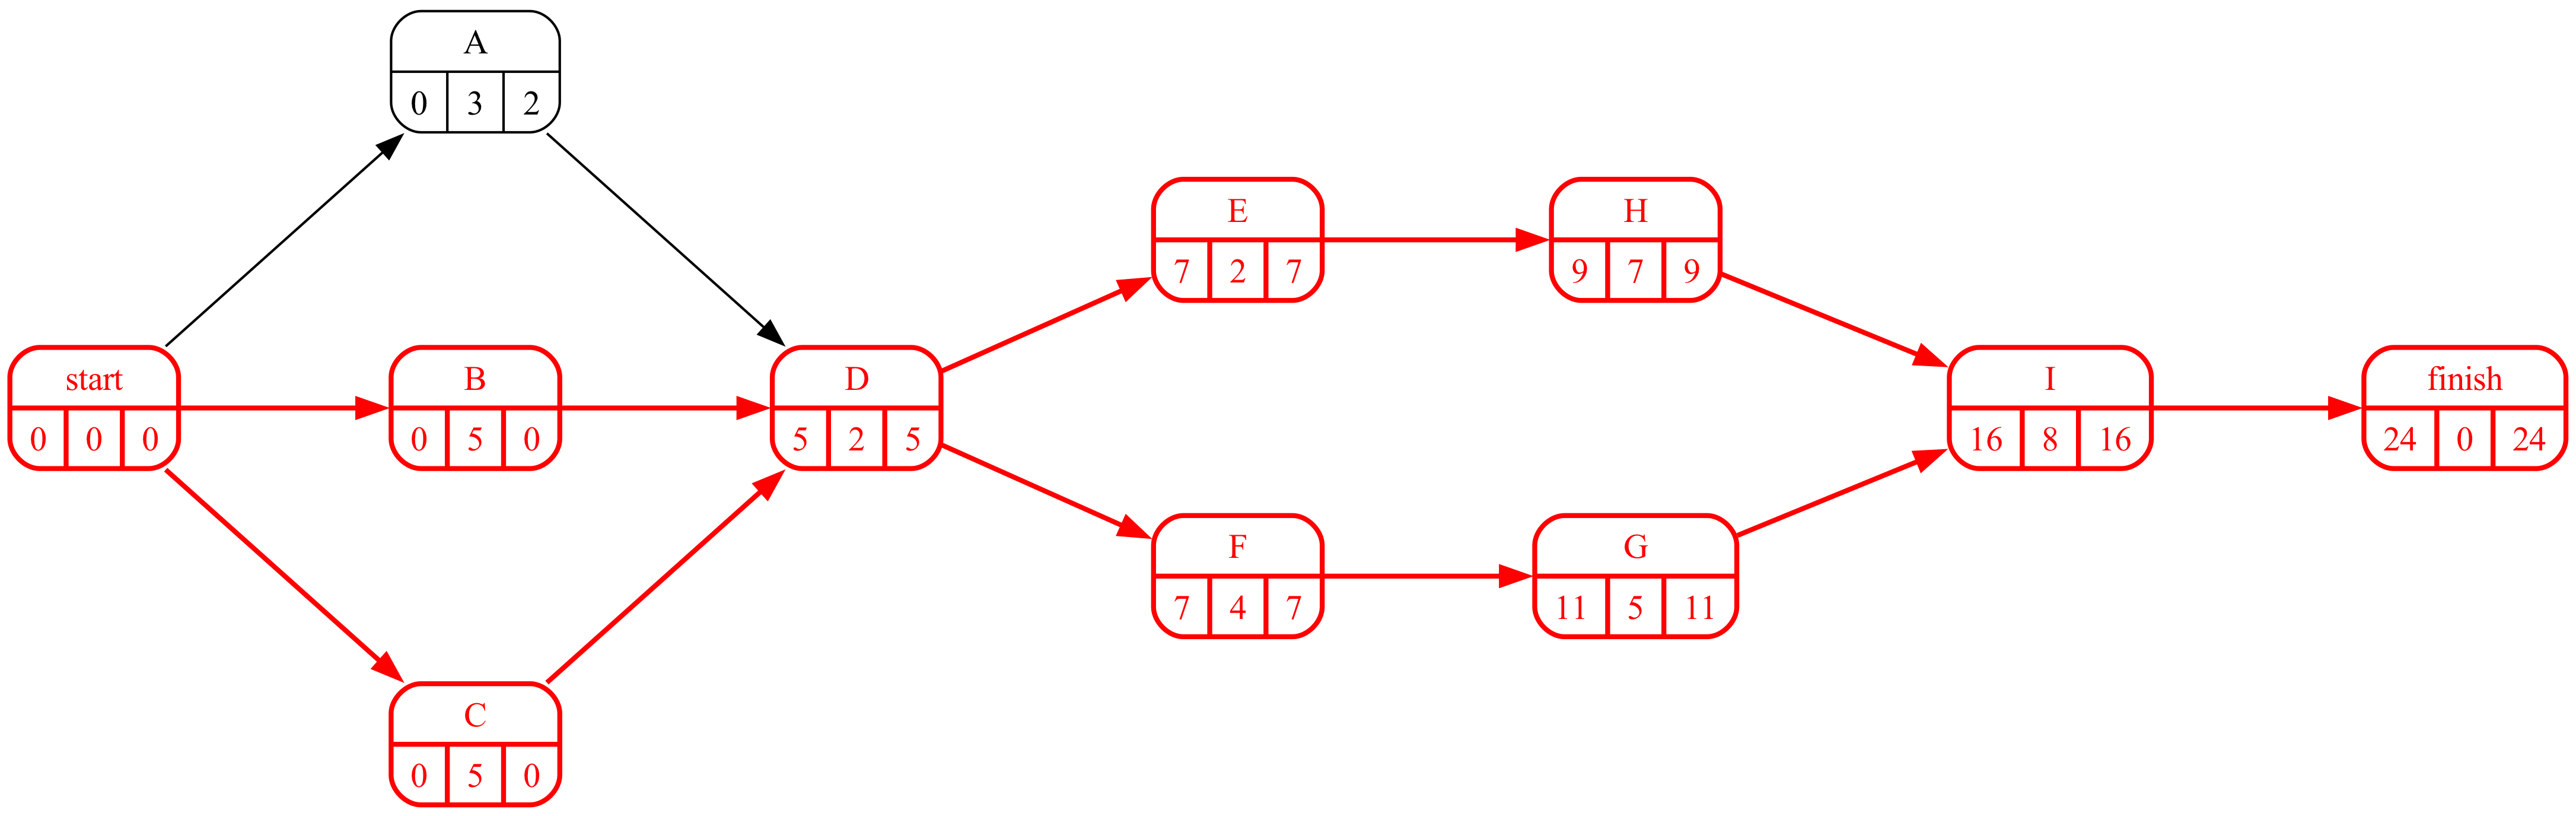

In [11]:
#| fig-cap: "Grafo Roy con las duraciones normales y el camino crítico"
#| label: fig-pert
proyecto.roy(durations=datos_proyecto['duration'], ranksep=1.2, nodesep=1.2)

In [12]:
duracion_normal = proyecto.duration(datos_proyecto['duration'])
coste_normal = int(datos_proyecto['cost_normal'].sum())
camino_critico = proyecto.display_critical_path(datos_proyecto['duration'])
Markdown(f'Con las duraciones normales el proyecto dura {duracion_normal} semanas y cuesta {coste_normal} k€.')

- Route_3 :	B, D, E, H, I <br> 

- Route_4 :	B, D, F, G, I <br> 

- Route_5 :	C, D, E, H, I <br> 

- Route_6 :	C, D, F, G, I <br> 

Con las duraciones normales el proyecto dura 24 semanas y cuesta 380 k€.

## Apartado 3

In [13]:
display(Markdown(pregunta_3))

3. Reduzca la duración del proyecto en 3 semanas con el mínimo sobrecoste aplicando el algoritmo de Ackoff-Sasieni paso a paso. Indique en cada paso qué actividad(es) se acortan y por qué.  

En cada paso del algoritmo de Ackoff-Sasieni se acorta una semana la ruta (o rutas) crítica(s) eligiendo, entre las actividades críticas con margen, la combinación de menor CUR que reduzca *todas* las rutas críticas a la vez. Cuando hay varias rutas críticas sin actividades comunes baratas hay que acortar una actividad de cada una, y el coste del paso es la suma. La tabla muestra, para cada ruta, el CUR de sus actividades y su duración tras cada paso; las últimas filas, el margen de reducción que le queda a cada actividad.

In [14]:
#| tbl-cap: "Algoritmo de Ackoff-Sasieni"
#| label: tbl-ackoff
tabla_ackoff, pasos, duraciones_reducidas, margen_restante = proyecto.ackoff(
    durations=datos_proyecto['duration'], min_durations=datos_proyecto['cap_duration'],
    costs=datos_proyecto['ucr'], reduction=3, report=False)
tabla_ackoff

,A,B,C,D,E,F,G,H,I,0,1,2,3
Route_1,inf,,,9.0,inf,,,4.0,3.0,22.0,21.0,20.0,20.0
Route_2,inf,,,9.0,,5.0,5.0,,3.0,22.0,21.0,20.0,20.0
Route_3,,2.0,,9.0,inf,,,4.0,3.0,24.0,23.0,22.0,21.0
Route_4,,2.0,,9.0,,5.0,5.0,,3.0,24.0,23.0,22.0,21.0
Route_5,,,5.0,9.0,inf,,,4.0,3.0,24.0,23.0,22.0,21.0
Route_6,,,5.0,9.0,,5.0,5.0,,3.0,24.0,23.0,22.0,21.0
0,0.0,1.0,2.0,1.0,0.0,2.0,1.0,2.0,2.0,,,,
1,0.0,1.0,2.0,1.0,0.0,2.0,1.0,2.0,1.0,,,,
2,0.0,1.0,2.0,1.0,0.0,2.0,1.0,2.0,0.0,,,,
3,0.0,0.0,1.0,1.0,0.0,2.0,1.0,2.0,0.0,,,,


Lo que se compara en cada paso: las rutas críticas en ese momento, las opciones que acortan todas a la vez (una actividad común con margen, o una pareja con una actividad de cada ruta) con su coste, y la elegida (la más barata).

In [15]:
#| tbl-cap: "Opciones consideradas en cada paso de Ackoff-Sasieni"
#| label: tbl-ackoffPaso
detalle_ackoff(proyecto, datos_proyecto['duration'], datos_proyecto['cap_duration'], datos_proyecto['ucr'], pasos)

,duración,rutas críticas,opciones (coste),elegida,coste del paso
paso,,,,,
1,24,"Route_3, Route_4, Route_5, Route_6",I (3); B+C (7); D (9); F+H (9); G+H (9),I,3.0
2,23,"Route_3, Route_4, Route_5, Route_6",I (3); B+C (7); D (9); F+H (9); G+H (9),I,3.0
3,22,"Route_3, Route_4, Route_5, Route_6",B+C (7); D (9); F+H (9); G+H (9),"B, C",7.0


In [16]:
resumen = pd.DataFrame({'actividades acortadas': [', '.join(acts) for acts in pasos.values()],
                        'sobrecoste del paso': [sum(datos_proyecto.loc[acts, 'ucr']) for acts in pasos.values()]},
                       index=pd.Index(range(1, len(pasos) + 1), name='paso'))
resumen['duración'] = duracion_normal - resumen.index
resumen['sobrecoste acumulado'] = resumen['sobrecoste del paso'].cumsum()
resumen

,actividades acortadas,sobrecoste del paso,duración,sobrecoste acumulado
paso,,,,
1,I,3.0,23,3.0
2,I,3.0,22,6.0
3,"B, C",7.0,21,13.0


## Apartado 4

In [17]:
display(Markdown(pregunta_4))

4. Indique el coste final del proyecto y su(s) nuevo(s) camino(s) crítico(s). ¿Por qué en algún paso ha hecho falta acortar más de una actividad a la vez?  

In [18]:
duracion_reducida = proyecto.duration(duraciones_reducidas)
coste_final = coste_normal + resumen['sobrecoste del paso'].sum()
camino_critico_reducido = proyecto.display_critical_path(duraciones_reducidas)
pasos_dobles = [p for p, acts in pasos.items() if len(acts) > 1]
Markdown(f'''El proyecto pasa a durar {duracion_reducida} semanas con un coste de {coste_normal} + {resumen["sobrecoste del paso"].sum():.0f} = {coste_final:.0f} k€. Al acortar la ruta crítica, otras rutas con holgura pequeña alcanzan su duración y pasan a ser críticas; a partir de ese momento reducir una sola actividad no basta, salvo que sea común a todas las rutas críticas, y hay que acortar una actividad de cada ruta (paso(s) {", ".join(str(p + 1) for p in pasos_dobles)}), con el coste sumado.''')

- Route_3 :	B, D, E, H, I <br> 

- Route_4 :	B, D, F, G, I <br> 

- Route_5 :	C, D, E, H, I <br> 

- Route_6 :	C, D, F, G, I <br> 

El proyecto pasa a durar 21 semanas con un coste de 380 + 13 = 393 k€. Al acortar la ruta crítica, otras rutas con holgura pequeña alcanzan su duración y pasan a ser críticas; a partir de ese momento reducir una sola actividad no basta, salvo que sea común a todas las rutas críticas, y hay que acortar una actividad de cada ruta (paso(s) 3), con el coste sumado.

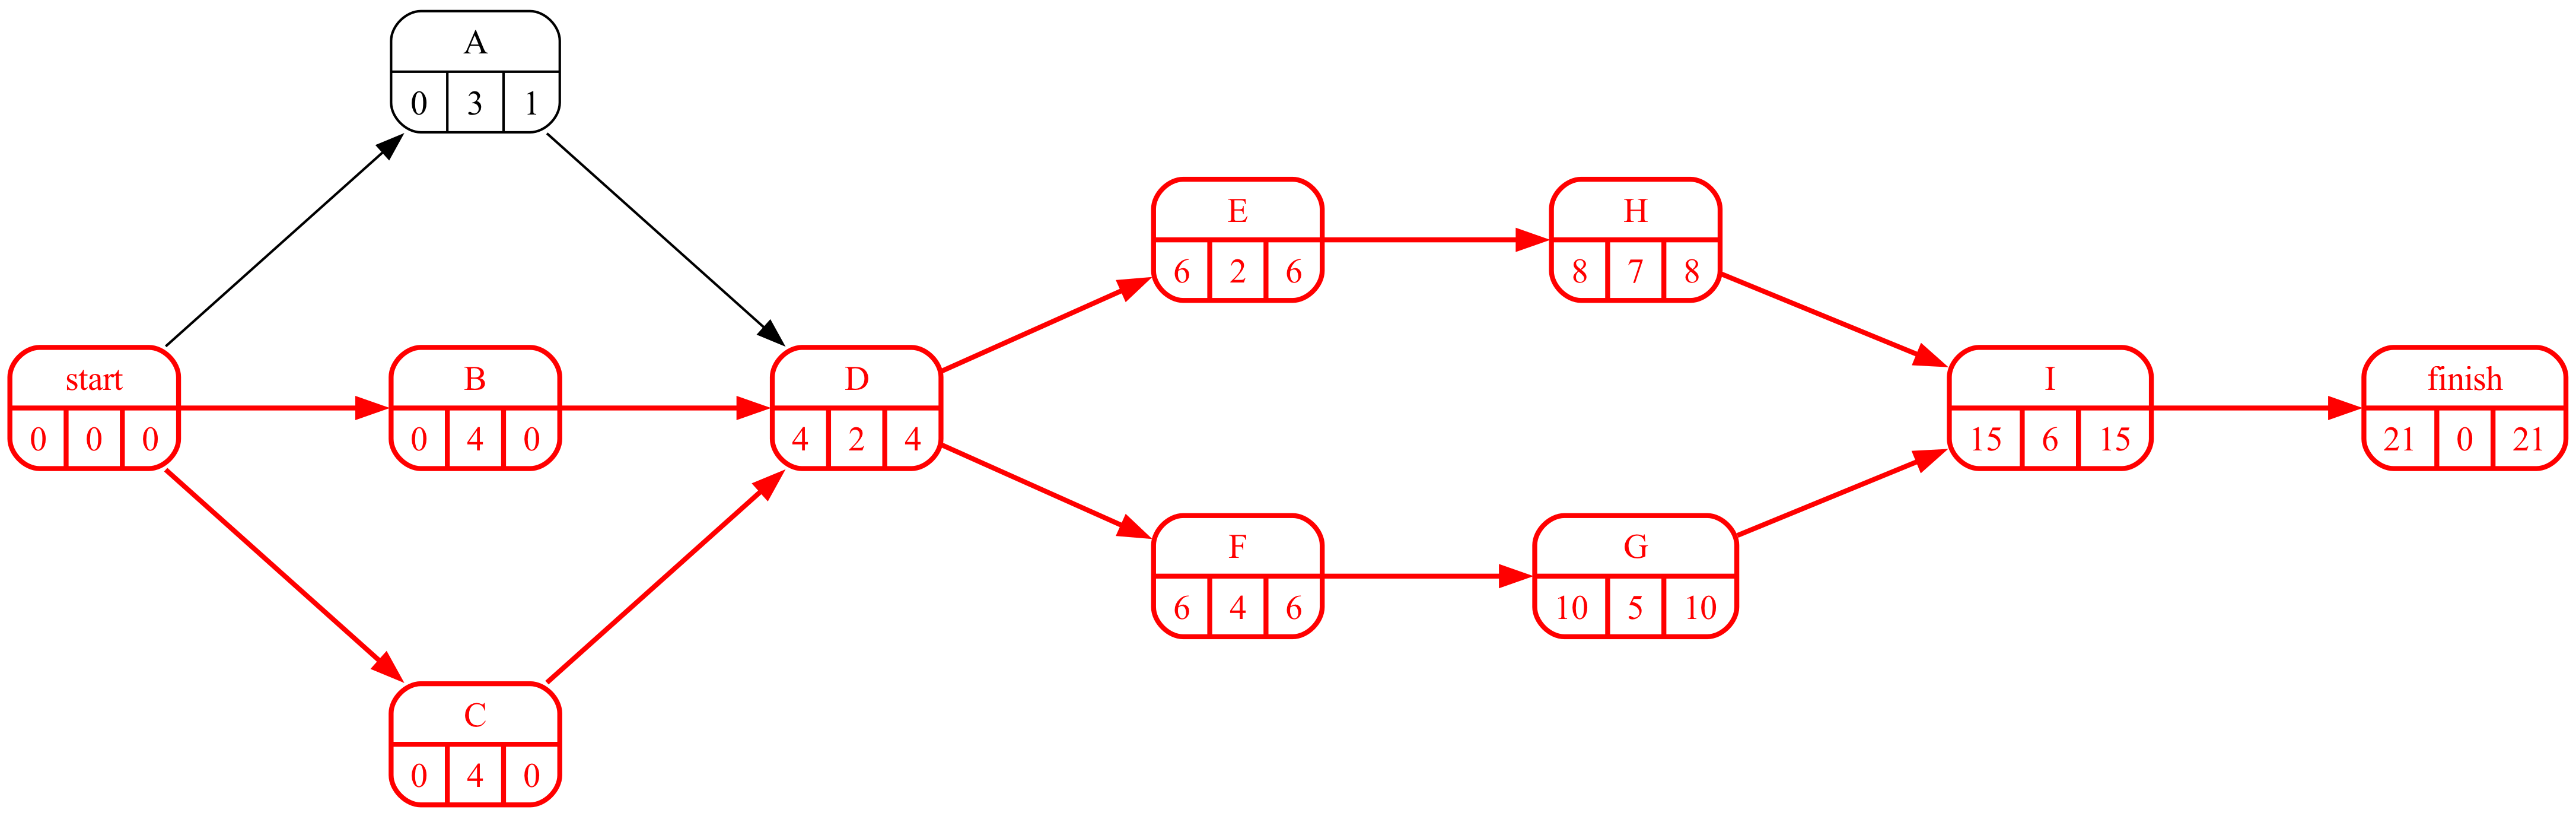

In [19]:
#| fig-cap: "Grafo Roy con las duraciones reducidas"
#| label: fig-pertReducido
proyecto.roy(durations=duraciones_reducidas, ranksep=1.2, nodesep=1.2)